# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називаються різні рівнини України? Як називаються різні рівнини України? Як називаються різні рівнини України? Як називаються різні рівнини України? Як називаються різні рівнини України? Як називаються різні рівнини України?


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [8]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [9]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 49.2 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 767 | генерація: 171.2 с
--- міркування (1862 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, she adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she added. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which is 8. So

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [10]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 251 | генерація: 56.2 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, потрібно поділити слово на склади і переглядати кожну літеру.

Слово: **трансформер**

Розбіяємо його на склади:

- **транс**  
- **формер**

Тепер переглядати кожну літеру:

- **транс** → **т**, **р**, **а**, **н**, **с**  
- **формер** → **ф**, **о**, **р**, **м**, **е**, **р**

Таким чином, літера **«р»** з'являється:

- У **транс** — 1 раз  
- У **формер** — 2 рази

**Всього:** 1 + 2 = **3 рази**

**Відповідь: 3 рази.**

=== think=True | токенів: 579 | генерація: 122.0 с
--- міркування (1353 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" (which is the Russian letter for "r") appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Wait, is that the correct spelling? Let me confirm. In Ukrainian, "трансформер" is t

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [14]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [15]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [16]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [2]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [17]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [18]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,17.80,2.67,2.40,55.22,23.71
int8,4.42,5.01,6.22,2.67,2.40,58.25,26.17
int4,2.73,3.32,3.04,2.81,2.76,55.34,29.79
int2,1.81,2.39,3.09,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

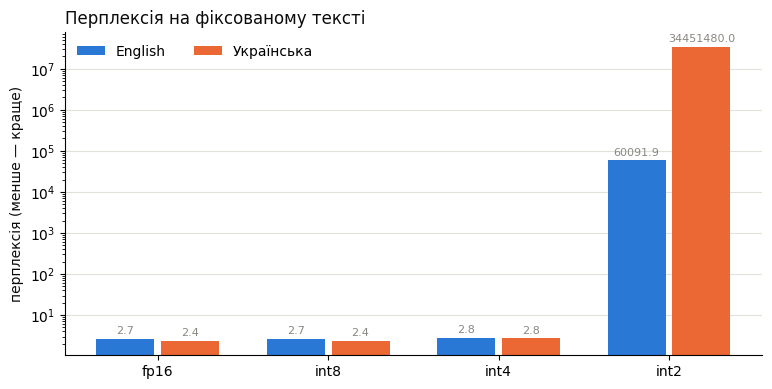

In [19]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [20]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [21]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [10]:
VOTES = {1: "", 2: "", 3: "", 4: "", 5: ""}

In [11]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [22]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

---

# Лабораторна робота №4. Локальний запуск і оптимізація моделей

**Тема:** локальний запуск і оптимізація великих мовних моделей.

У роботі досліджено локальний запуск моделей сімейства Qwen3 за допомогою Ollama, порівняно швидкодію двох розмірів моделей, а також створено вебзастосунок AI Code Assistant.

> Примітка щодо виконання: початкові демонстраційні клітинки ноутбука потрібно виконати в середовищі з Ollama та GPU. Результати, що залежать від запуску демонстрації (перплексія, метрики перекладу, сліпе порівняння), слід заповнювати за фактичним виводом клітинок, а не підставляти приблизні значення.


## 0.1. Відповіді на контрольні питання до демо

### 1. Чому модель неправильно рахує літеру «р»?

Модель працює з токенами, а не з окремими буквами. Тому вона не завжди правильно рахує символи у словах. Для точного підрахунку краще використовувати програмний код.

```python
word = "трансформер"
print(word.count("р"))
```

Результат: `3`.

### 2. Як змінюються перплексія та метрики перекладу?

Під час переходу від FP16 до INT2 перплексія зростає, а BLEU та chrF зазвичай знижуються. Це означає, що якість передбачення тексту та перекладу погіршується. Найбільший стрибок потрібно визначити за результатами таблиці 2.4.

### 3. Чи однаково зростає перплексія для англійської та української?

Ні, зміни можуть відрізнятися. Мови по-різному обробляються токенізатором, тому квантизація може впливати на них неоднаково. Порівнювати перплексію потрібно окремо для кожної мови.

### 4. Чи збігається сліпе порівняння з автоматичними метриками?

Не обов'язково. Автоматичні метрики оцінюють збіг тексту з еталоном, а людина враховує зміст і правильність відповіді. Тому модель може отримати нижчі оцінки, але надати правильний за змістом переклад.

### 5. Чому правильний переклад може мати низькі BLEU і chrF?

Тому що переклад може відрізнятися від еталона словами або порядком слів, хоча його зміст правильний. BLEU і chrF враховують текстову схожість, тому можуть знижувати оцінку такого перекладу.

### 6. Чому пам'ять зменшується не точно вдвічі, вчетверо чи увосьмеро?

Теоретично INT8 займає вдвічі менше пам'яті, INT4 — у чотири рази, а INT2 — у вісім разів менше порівняно з FP16. Але фактично є додаткові витрати на метадані квантизації та службові дані. Швидкість генерації може збільшуватися, але це залежить від обладнання та реалізації.

### 7. Чому Base-модель відповідає новими питаннями?

Base-модель навчена продовжувати текст, а не виконувати інструкції. Щоб отримати відповідь, потрібно чіткіше сформулювати промпт.

```python
prompt = """
Дай коротку відповідь на запитання.
Не став зустрічних запитань.
Запитання: Яка столиця Франції?
Відповідь:
"""
print(generate_raw(BASE_MODEL, prompt))
```

Очікувана відповідь: Париж.

### 8. Скільки токенів і часу забирають міркування?

Режим міркування використовує додаткові токени та час перед формуванням відповіді. Модель може міркувати англійською, оскільки значна частина навчальних даних представлена цією мовою. Точні показники потрібно взяти з результатів розділу 1.4.

### 9. Коли режим міркування допомагає?

Він корисний для задач, які потребують кількох послідовних кроків: математичних обчислень, логіки та аналізу коду. Міркування може допомогти знайти правильну відповідь, коли звичайна генерація помиляється. Приклад потрібно взяти з фактичного запуску демо.

### 10. Для чого використовуються temperature = 0 і seed = 1?

`temperature = 0` зменшує випадковість відповідей. `seed = 1` задає початкове значення генератора випадкових чисел. Це допомагає отримувати більш стабільні результати під час експериментів.

### 11. Чому використовується FP16, а не BF16?

У демо використовується відеокарта NVIDIA T4. Її обчислювальна здатність:

```python
torch.cuda.get_device_capability()
```

Результат: `(7, 5)`. Для цієї відеокарти FP16 є сумісним варіантом, тому в експерименті використовується саме він.

### 12. Скільки пам'яті займає FP16-модель?

У розділі 2.1 використовується Qwen3-4B, яка має приблизно 4 мільярди параметрів.

Формула:

\[
M = \frac{N \cdot B}{8}
\]

\[
M = \frac{4 \cdot 10^9 \cdot 16}{8}
= 8 \text{ GB}
\]

Отже, теоретично FP16-модель займає приблизно 8 GB пам'яті.

### 13. Що таке перплексія?

Перплексія показує, наскільки добре модель передбачає наступні токени тексту. Чим менше значення, тим краще модель передбачає текст. Її не можна безпосередньо порівнювати між англійською та українською, оскільки токенізатор по-різному розбиває ці мови на токени. На випадковому наборі слів перплексія буде вищою через відсутність логічного зв'язку між словами.

### 14. Чому пік VRAM більший за пам'ять моделі?

Крім ваг моделі, під час генерації пам'ять займають KV-кеш, проміжні обчислення, активації та службові буфери CUDA. Тому загальне використання відеопам'яті стає більшим.

### 15. Наскільки надійне сліпе порівняння з п'яти запитів?

П'яти порівнянь недостатньо для впевненого висновку. Результат може залежати від конкретних запитань. Для більш надійної оцінки потрібно провести щонайменше 30–50 порівнянь.

Мої результати: FP16 — ___, INT4 — ___, однаково — ___.

### 16. Як модель помиляється в INT2?

У INT2 якість відповідей помітно погіршується. Модель може повторювати текст, давати нелогічні відповіді, помилятися у фактах та неправильно виконувати інструкції. В INT4 такі проблеми зазвичай менш виражені.

### 17. Чи сильніше квантизація впливає на меншу модель?

Менша модель може бути чутливішою до втрати точності, оскільки має менше параметрів для збереження складних закономірностей. Для підтвердження цього потрібно порівняти перплексію та chrF моделей 1.7B і 4B після квантизації.

### 18. Для чого потрібен OLLAMA_NUM_PARALLEL?

Цей параметр визначає кількість запитів, які Ollama може обробляти паралельно. Збільшення його значення дозволяє обслуговувати більше запитів одночасно, але потребує більше оперативної та відеопам'яті.

### 19. Чому сучасні моделі часто зберігаються у BF16?

BF16 займає 16 біт, як і FP16, але має ширший діапазон значень. Це допомагає уникати переповнення під час обчислень. Тому цей формат зручний для навчання та зберігання великих моделей.

### 20. Для чого використовується OpenAI-сумісний API?

OpenAI API став поширеним інтерфейсом для роботи з мовними моделями. Завдяки сумісності можна використовувати однаковий код для різних моделей і рантаймів. Наприклад, Ollama дозволяє звертатися до локальної моделі через OpenAI Python SDK. При цьому запити обробляються локально, а не ChatGPT.

## 1.1. Характеристики апаратного забезпечення

Експерименти виконувалися на персональному ноутбуці з такими характеристиками:

| Компонент | Характеристика | Джерело / спосіб визначення |
|---|---|---|
| Процесор | AMD Ryzen 5 5600H | Відомості про систему / CPU |
| Ядра / потоки | 6 / 12 | Характеристики процесора |
| Оперативна пам'ять | 16 ГБ DDR4 | Відомості про систему |
| Конфігурація RAM | 2 × 8 ГБ, двоканальний режим | Відомості про модулі пам'яті |
| Частота RAM | 3200 MT/s | Характеристики пам'яті |
| Відеокарта | NVIDIA GeForce RTX 3050 Laptop GPU | Диспетчер пристроїв / `nvidia-smi` |
| Відеопам'ять | 4 ГБ GDDR6 | `nvidia-smi` / специфікація GPU |
| Пропускна здатність VRAM | орієнтовно 192 ГБ/с | Теоретична характеристика RTX 3050 Laptop |
| Теоретична пропускна здатність RAM | 51,2 ГБ/с | Розрахунок нижче |

### Розрахунок пропускної здатності оперативної пам'яті

Для двоканальної DDR4-3200 теоретична пропускна здатність:

$$
BW_{RAM}=R\cdot W\cdot C
$$

де:
- $R=3200\cdot10^6$ передач/с — ефективна швидкість DDR4-3200;
- $W=8$ байт — ширина одного 64-бітного каналу;
- $C=2$ — кількість каналів.

Підставляємо:

$$
BW_{RAM}=3200\cdot10^6\cdot8\cdot2
=51\,200\,000\,000\text{ байт/с}
$$

$$
\boxed{BW_{RAM}=51{,}2\text{ ГБ/с}}
$$

Це теоретичне значення. Реальна пропускна здатність може бути нижчою через накладні витрати контролера пам'яті та характер доступу до даних.


## 1.2. Ручні розрахунки бюджету пам'яті та швидкодії

Для розрахунків обрано Qwen3 1.7B, яка використовується як основна модель у власному застосунку. Довжина контексту застосунку — 4096 токенів.

### 1.2.1. Оцінка обсягу ваг моделі

Теоретичний обсяг ваг обчислюється за формулою:

$$
M_{weights}=\frac{N\cdot B}{8}
$$

де:
- $N$ — кількість параметрів моделі;
- $B$ — кількість біт для зберігання одного параметра;
- результат отримуємо в байтах.

Для Qwen3 1.7B:

$$
N=1{,}7\cdot10^9\text{ параметрів}
$$

**FP16 (16 біт на параметр):**

$$
M_{FP16}=\frac{1{,}7\cdot10^9\cdot16}{8}
=3{,}4\cdot10^9\text{ байт}
$$

$$
\boxed{M_{FP16}\approx3{,}4\text{ ГБ}}
$$

**INT8 (8 біт на параметр):**

$$
M_{INT8}=\frac{1{,}7\cdot10^9\cdot8}{8}
=1{,}7\cdot10^9\text{ байт}
$$

$$
\boxed{M_{INT8}\approx1{,}7\text{ ГБ}}
$$

**INT4 (4 біти на параметр):**

$$
M_{INT4}=\frac{1{,}7\cdot10^9\cdot4}{8}
=0{,}85\cdot10^9\text{ байт}
$$

$$
\boxed{M_{INT4}\approx0{,}85\text{ ГБ}}
$$

**INT2 (2 біти на параметр):**

$$
M_{INT2}=\frac{1{,}7\cdot10^9\cdot2}{8}
=0{,}425\cdot10^9\text{ байт}
$$

$$
\boxed{M_{INT2}\approx0{,}425\text{ ГБ}}
$$

Отримані значення є теоретичними оцінками. Реальні файли моделей займають більше місця через службові дані, масштаби та групи квантизації, словник токенізатора й інші компоненти.

### 1.2.2. Розрахунок KV-кешу

Під час генерації трансформер зберігає ключі (Key) та значення (Value) для токенів контексту. Обсяг KV-кешу на один токен:

$$
KV_{token}=2\cdot L\cdot H_{kv}\cdot D_h\cdot S
$$

де:
- $2$ — окремо Key та Value;
- $L=28$ — кількість шарів Qwen3 1.7B;
- $H_{kv}=8$ — кількість KV-голів;
- $D_h=128$ — розмір однієї голови;
- $S=2$ байти — FP16 для кожного елемента кешу.

Підставляємо:

$$
KV_{token}=2\cdot28\cdot8\cdot128\cdot2
=114\,688\text{ байт}
$$

Переводимо в KiB:

$$
KV_{token}=\frac{114\,688}{1024}=112\text{ KiB}
$$

Для контексту 4096 токенів:

$$
KV_{4096}=112\cdot4096=458\,752\text{ KiB}
$$

$$
KV_{4096}=448\text{ MiB}=0{,}4375\text{ GiB}
$$

$$
\boxed{KV_{4096}\approx448\text{ MiB на один запит}}
$$

Це оцінка для FP16 KV-кешу, одного запиту та повністю заповненого контексту 4096 токенів. За кількох одночасних запитів потреба в KV-кеші приблизно пропорційно зростає.

### 1.2.3. Загальна оцінка пам'яті

Для ілюстративної оцінки додаємо до ваг KV-кеш одного запиту:

$$
M_{total}\approx M_{weights}+KV_{4096}
$$

Для INT4:

$$
M_{total,INT4}\approx0{,}85+0{,}4375
=1{,}2875\text{ ГБ}
$$

Для INT8:

$$
M_{total,INT8}\approx1{,}7+0{,}4375
=2{,}1375\text{ ГБ}
$$

Для FP16:

$$
M_{total,FP16}\approx3{,}4+0{,}4375
=3{,}8375\text{ ГБ}
$$

| Формат ваг | Теоретичний обсяг ваг | Ваги + KV-кеш 4096 | Оцінка для VRAM 4 ГБ |
|---|---:|---:|---|
| FP16 | 3,40 ГБ | 3,84 ГБ | Дуже тісно, без запасу на рантайм |
| INT8 | 1,70 ГБ | 2,14 ГБ | Потенційно поміщається, але потрібен запас |
| INT4 | 0,85 ГБ | 1,29 ГБ | Найбільш реалістичний варіант |
| INT2 | 0,425 ГБ | 0,86 ГБ | За пам'яттю поміщається, але якість може погіршитися |

Окрім ваг та KV-кешу, рантайму потрібна додаткова пам'ять для буферів, обчислень і службових структур. Тому фактичний обсяг буде більшим за оцінку в таблиці. Для ноутбука з 4 ГБ VRAM доцільно використовувати квантизовану модель і не планувати повне заповнення відеопам'яті.

**Примітка:** у таблиці наведені теоретичні розміри для рівномірної квантизації. Вони не є підтвердженням конкретного формату файлу `qwen3:1.7b` у встановленому Ollama. Точний формат можна перевірити командою `ollama show qwen3:1.7b`.

### 1.2.4. Оцінка верхньої межі швидкості генерації

Згідно з лекцією, швидкість генерації обмежується пропускною здатністю пам'яті:

$$
tokens/s\lesssim\frac{BW}{M_{token}}
$$

Для приблизної оцінки беремо теоретичні INT4-ваги та KV-кеш контексту 4096:

$$
M_{token}\approx0{,}85+0{,}4375
=1{,}2875\text{ ГБ}
$$

Для RTX 3050 Laptop із пропускною здатністю близько 192 ГБ/с:

$$
tokens/s\lesssim\frac{192}{1{,}2875}
\approx149{,}1
$$

$$
\boxed{tokens/s\lesssim149\text{ токенів/с}}
$$

Для двоканальної оперативної пам'яті DDR4-3200:

$$
tokens/s\lesssim\frac{51{,}2}{1{,}2875}
\approx39{,}8
$$

Ці значення є спрощеною теоретичною верхньою оцінкою, а не гарантованою швидкістю. Вона не враховує обчислювальні обмеження GPU/CPU, реальний розмір файлу квантизованої моделі, службові буфери та особливості розподілу шарів між CPU і GPU.


## 1.3. Вибір моделі та рантайму

Для локального запуску обрано **Ollama**, оскільки вона дозволяє завантажувати та запускати моделі локально, а також надає API, сумісний з OpenAI API.

Для експериментів використано:
- `qwen3:1.7b` — основна Instruct-модель;
- `qwen3:0.6b` — менша модель для порівняння швидкодії.

Для власного застосунку залишено Qwen3 1.7B. Під час ручного порівняння відповідей менша модель частіше допускала помилки в поясненні програмного коду та SQL. Тому більша модель виявилася кращим компромісом між якістю та швидкістю.

Модель запускається локально через Ollama та викликається з Python-застосунку за адресою `http://localhost:11434/v1`. У застосунку використовується OpenAI Python SDK.

Для відповідей у застосунку задано `temperature = 0.4`, максимальну довжину відповіді 1024 токени та контекст 4096 токенів.


## 1.4. Вимірювання до оптимізації

Початкове вимірювання виконано для `qwen3:1.7b` з міткою `before`. Для коректного порівняння використано рядки CSV, у яких `reasoning = False` та `errors = 0`. Перший запуск із `reasoning = True` не включено до порівняння: він мав помилки запитів і додаткові витрати на генерацію міркувань.

Результати початкового вимірювання:

| Паралельні клієнти | TTFT p50, с | TTFT p95, с | Швидкість на користувача p50, токенів/с | Загальний throughput, токенів/с | Помилки |
|---:|---:|---:|---:|---:|---:|
| 1 | 2,130 | 2,158 | 77,5 | 34,8 | 0 |
| 2 | 2,469 | 3,766 | 82,2 | 65,0 | 0 |
| 4 | 8,916 | 15,053 | 47,0 | 40,1 | 0 |
| 8 | 11,798 | 20,633 | 84,3 | 62,4 | 0 |

**TTFT** — час від надсилання запиту до отримання першого токена. p50 — медіанне значення, p95 — значення, швидше за яке завершилися 95% вимірювань. Швидкість на користувача та загальний throughput — різні показники: throughput показує сумарну продуктивність усіх одночасних запитів.


## 1.5. Оптимізація та повторне вимірювання

Як оптимізацію було обрано перехід від `qwen3:1.7b` до меншої `qwen3:0.6b`. Це оптимізація шляхом зменшення розміру моделі, а не зміна квантизації тієї самої моделі.

Результати після зміни моделі:

| Паралельні клієнти | TTFT p50, с | TTFT p95, с | Швидкість на користувача p50, токенів/с | Загальний throughput, токенів/с | Помилки |
|---:|---:|---:|---:|---:|---:|
| 1 | 2,105 | 2,138 | 131,4 | 39,7 | 0 |
| 2 | 2,102 | 2,605 | 158,7 | 77,9 | 0 |
| 4 | 2,420 | 3,807 | 159,8 | 127,4 | 0 |
| 8 | 5,236 | 7,337 | 159,9 | 131,9 | 0 |

### Розрахунок приросту швидкості

Відсоток приросту швидкості обчислюємо за формулою:

$$
P=\frac{V_{after}-V_{before}}{V_{before}}\cdot100\%
$$

Для одного клієнта:

$$
P_1=\frac{131{,}4-77{,}5}{77{,}5}\cdot100\%
$$

$$
P_1=69{,}55\%
$$

Для двох клієнтів:

$$
P_2=\frac{158{,}7-82{,}2}{82{,}2}\cdot100\%
$$

$$
P_2\approx93{,}07\%
$$

Для чотирьох клієнтів:

$$
P_4=\frac{159{,}8-47{,}0}{47{,}0}\cdot100\%
=240\%
$$

Для восьми клієнтів:

$$
P_8=\frac{159{,}9-84{,}3}{84{,}3}\cdot100\%
$$

$$
P_8\approx89{,}68\%
$$

| Клієнти | До, токенів/с | Після, токенів/с | Приріст |
|---:|---:|---:|---:|
| 1 | 77,5 | 131,4 | 69,55% |
| 2 | 82,2 | 158,7 | 93,07% |
| 4 | 47,0 | 159,8 | 240,00% |
| 8 | 84,3 | 159,9 | 89,68% |

За результатами вимірювань менша модель показала вищу швидкість генерації для всіх перевірених рівнів паралельності. Найбільший відносний приріст швидкості на одного користувача отримано для чотирьох паралельних клієнтів — 240%.

Водночас швидкість не є єдиним критерієм. Під час перевірки однакових за змістом програмістських запитів модель 0.6B частіше помилялася або надавала неповні пояснення. Тому для застосунку було залишено Qwen3 1.7B.


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Таблиця побудована з bench_results.csv.
# Для порівняння беремо лише успішні запити без режиму reasoning.
bench = pd.read_csv("bench_results.csv")
bench = bench[(bench["reasoning"] == False) & (bench["errors"] == 0)]

before = bench[bench["label"] == "before"].sort_values("concurrency")
after = bench[bench["label"] == "after"].sort_values("concurrency")

comparison = pd.DataFrame({
    "Клієнти": before["concurrency"].to_numpy(),
    "До, токенів/с": before["tokens_per_s_per_user_p50"].to_numpy(),
    "Після, токенів/с": after["tokens_per_s_per_user_p50"].to_numpy(),
})
comparison["Приріст, %"] = (
    (comparison["Після, токенів/с"] - comparison["До, токенів/с"])
    / comparison["До, токенів/с"] * 100
).round(2)

display(comparison)

plt.figure(figsize=(8, 4))
plt.plot(comparison["Клієнти"], comparison["До, токенів/с"], marker="o", label="До оптимізації")
plt.plot(comparison["Клієнти"], comparison["Після, токенів/с"], marker="o", label="Після оптимізації")
plt.xlabel("Кількість паралельних клієнтів")
plt.ylabel("Токенів за секунду на користувача (p50)")
plt.title("Порівняння швидкості генерації")
plt.xticks(comparison["Клієнти"])
plt.grid(True)
plt.legend()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'bench_results.csv'

## 1.6. Розробка власного застосунку

Розроблено вебзастосунок **AI Code Assistant** на Python із використанням Gradio. Застосунок взаємодіє з локальною моделлю `qwen3:1.7b`, запущеною в Ollama через OpenAI-сумісний API.

Застосунок містить три основні розділи:

1. **AI-чат** — користувач може ставити запитання з програмування та отримувати відповіді моделі.
2. **Аналізатор коду** — пошук помилок, виправлення, пояснення та оптимізація програмного коду. Для синтаксичної перевірки Python використовується модуль `ast`.
3. **Генератор коду** — створення програм за текстовим описом користувача для вибраної мови програмування.

Параметри генерації:
- модель: `qwen3:1.7b`;
- temperature: `0.4`;
- максимальна кількість токенів відповіді: `1024`;
- довжина контексту: `4096`.

Для взаємодії з моделлю використовується локальний сервер Ollama за адресою `http://localhost:11434/v1`. Інтерфейс реалізовано засобами Gradio.


## 1.7. Тестування застосунку

Було виконано функціональне тестування основних можливостей AI Code Assistant.

| № | Тестовий сценарій | Очікуваний результат | Фактичний результат |
|---:|---|---|---|
| 1 | Надсилання запитання в AI-чат | Модель повертає відповідь | Пройдено |
| 2 | Продовження діалогу | Історія попередніх повідомлень зберігається | Пройдено |
| 3 | Пошук синтаксичної помилки Python | Виявляється незакрита дужка | Пройдено |
| 4 | Виправлення коду | Повертається виправлений код | Пройдено |
| 5 | Пояснення коду | Надається опис логіки програми | Частково |
| 6 | Оптимізація коду | Повертається оптимізований варіант | Пройдено |
| 7 | Генерація програми керування студентами | Створюється програма з меню, додаванням і переглядом студентів | Пройдено |
| 8 | Порожній опис у генераторі | Показується повідомлення про необхідність описати програму | Пройдено |

### Виявлений недолік моделі

Під час пояснення програми для обчислення середнього бала модель неправильно виконала арифметичну дію: замість правильного результату 10,25 навела 7,75. Це свідчить про те, що мовна модель може помилятися навіть у простих обчисленнях. Для зменшення ризику такі результати потрібно перевіряти окремо, а обчислення за можливості виконувати програмно.

Під час перевірки генератора було створено програму керування списком студентів. Перевірено додавання студента та відображення його у списку. Програма виводила меню повторно після виконання операції.


## 1.8. Висновки

Під час лабораторної роботи було досліджено локальний запуск великих мовних моделей за допомогою Ollama та виконано оцінку апаратних ресурсів комп'ютера. Для Qwen3 1.7B вручну розраховано теоретичний обсяг ваг для різних форматів представлення, обсяг KV-кешу для контексту 4096 токенів і приблизну верхню межу швидкості генерації.

Було проведено вимірювання швидкодії двох моделей: Qwen3 1.7B до оптимізації та Qwen3 0.6B після зміни моделі. За результатами тестів менша модель забезпечила вищу швидкість генерації, однак поступалася за якістю відповідей на програмістські запити. Тому для власного застосунку було обрано Qwen3 1.7B як компроміс між швидкодією та якістю.

Також було створено вебзастосунок AI Code Assistant, який надає можливість спілкуватися з локальною моделлю, аналізувати, виправляти, пояснювати, оптимізувати та генерувати програмний код. Функціональне тестування підтвердило роботу основних можливостей застосунку. Водночас виявлено обмеження моделі під час арифметичних обчислень, що підкреслює необхідність перевірки згенерованих відповідей.

Отже, мету лабораторної роботи досягнуто: отримано практичний досвід локального розгортання мовних моделей, оцінювання їхніх ресурсних вимог, вимірювання продуктивності та створення програмного застосунку на основі локальної LLM.
